# Task 1 – Anti-Cheat Pre-Filter: Exploratory Data Analysis

**Goal:** understand the data before we build the `is_cheater` classifier.
The metric is **F2**, so recall counts 4× more than precision.

Questions this notebook answers:

1. What does the target look like? Is it balanced? Is it complete?
2. How much data is missing, where, and does missingness carry signal?
3. Are train and test from the same distribution?
4. Which features separate cheaters from legitimate players – alone and together?
5. What do these facts mean for the model, the validation, and the threshold?

Each section has one short note on *why*, one cell per step, and a **Finding** line.
Figures go to `assets/eda/` (300 dpi). The last section lists the decisions for modeling.

> Rule check: test rows appear here only for **unsupervised** comparisons (missing rates,
> adversarial validation). No test row enters model fitting.

## 0. Setup

Imports. `HistGradientBoostingClassifier` handles NaN natively, so the probes need no imputation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency, ks_2samp
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, fbeta_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Paths, constants, and one fixed seed so every result is reproducible.

In [2]:
# Task root = nearest folder with pyproject.toml, so the notebook runs from any working directory.
TASK_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = TASK_DIR / "data"
ASSETS_DIR = TASK_DIR / "assets" / "eda"
ASSETS_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "is_cheater"
ID_COL = "player_id"
SEED = 42

Plot style. One fixed color per class everywhere: **blue = legitimate**, **orange = cheater**.
Correlation maps use a diverging blue–gray–orange scale; rates use a single-hue blue scale.

In [3]:
C_LEGIT, C_CHEAT, C_THIRD = "#2a78d6", "#eb6834", "#1baf7a"
CLASS_COLORS = {0: C_LEGIT, 1: C_CHEAT}
CLASS_NAMES = {0: "Legitimate", 1: "Cheater"}
DIVERGING = LinearSegmentedColormap.from_list("div", [C_LEGIT, "#e8e7e3", C_CHEAT])
SEQUENTIAL = "Blues"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": "#e6e6e6",
    "axes.titleweight": "bold",
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)

Helper: save every report figure the same way (PNG, 300 dpi, tight box).

In [4]:
def save_fig(fig, name):
    path = ASSETS_DIR / f"{name}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"saved {path.relative_to(TASK_DIR)}")

## 1. Load and inspect

Read the Kaggle files. `datacard.txt` describes each column.

In [5]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print(f"train: {train.shape}   test: {test.shape}")

train: (104000, 33)   test: (25889, 32)


First rows – check that the columns parsed correctly.

In [6]:
train.head()

,player_id,kill_death_ratio,headshot_percentage,win_rate,accuracy_score,kill_consistency,reaction_time_ms,account_age_days,level,level_progression_speed,friend_network_size,reports_received,device_changes_count,input_consistency_score,avg_session_length_min,sessions_per_day,night_play_ratio,weapon_switch_speed,movement_pattern_score,aiming_smoothness,spray_control_score,game_sense_score,communication_rate,team_play_score,buy_decision_score,map_knowledge,clutch_success_rate,first_blood_rate,survival_time_avg,damage_per_round,utility_usage_rate,crosshair_placement,is_cheater
0,P001337,5.1762,54.2455,85.6629,25.4578,0.7749,83.8281,261.7210,34.0091,0.0229,236.0000,18.0000,6.0000,0.6774,95.8873,0.4740,0.2273,0.8530,0.5712,0.7535,NaN,0.9732,0.4675,0.6921,0.8344,0.5507,0.4911,0.4831,73.4760,55.7114,0.7906,0.8930,0.0000
1,P044854,6.5104,54.3886,99.1746,36.6796,0.8133,148.2957,1075.7048,72.8636,0.0673,245.0000,6.0000,NaN,0.7506,NaN,4.0143,0.6527,NaN,0.8120,0.8522,0.8023,0.7060,0.7336,0.6164,0.8530,0.5564,0.5620,NaN,NaN,NaN,0.7937,0.9568,0.0000
2,P036798,5.4572,60.4179,100.0000,44.5587,0.7209,117.6630,1031.5401,99.0754,0.0552,200.0000,11.0000,NaN,0.6801,237.5642,5.9443,0.2430,0.8068,0.5511,0.9769,0.6946,0.7747,NaN,NaN,0.3626,0.5797,0.1297,0.3358,40.7844,NaN,0.5636,0.8683,0.0000
3,P079617,NaN,35.1807,67.7569,42.7509,0.3799,348.4636,525.5344,39.6947,0.0290,63.0000,NaN,2.0000,0.6008,81.0648,8.0100,0.4370,0.6003,0.5323,0.8330,0.6486,0.8987,0.2620,0.5015,0.3982,0.6307,0.5130,0.1790,60.1851,135.3412,NaN,0.9388,NaN
4,P093830,3.7478,31.7780,80.6898,26.8208,0.5673,351.8198,296.1796,72.8175,0.0406,74.0000,11.0000,2.0000,0.5151,194.1422,5.3665,NaN,NaN,0.7010,0.6415,0.6335,0.7159,0.4578,0.5487,0.4854,0.5781,0.4210,0.1549,59.3599,127.0756,0.4719,0.8374,NaN


Feature list: every column except the id and the target.

In [7]:
FEATURES = [c for c in train.columns if c not in (ID_COL, TARGET)]
print(f"{len(FEATURES)} features")
assert FEATURES == [c for c in test.columns if c != ID_COL], "train/test columns differ"

31 features


Schema: type, distinct values, and range. Low distinct counts mark count-like (discrete) features.

In [8]:
schema = pd.DataFrame({
    "dtype": train[FEATURES].dtypes.astype(str),
    "n_unique": train[FEATURES].nunique(),
    "min": train[FEATURES].min(),
    "max": train[FEATURES].max(),
}).sort_values("n_unique")
schema

,dtype,n_unique,min,max
device_changes_count,float64,16,0.0000,15.0000
reports_received,float64,26,4.0000,29.0000
friend_network_size,float64,350,0.0000,349.0000
aiming_smoothness,float64,75614,0.3230,1.0000
survival_time_avg,float64,78695,8.9286,107.9987
weapon_switch_speed,float64,78787,0.2699,0.9100
avg_session_length_min,float64,80105,25.0068,274.9971
movement_pattern_score,float64,80676,0.3131,0.9400
communication_rate,float64,82598,0.2200,0.8800
spray_control_score,float64,83181,0.3500,1.0000


**Finding:** all 31 features are numeric floats. Three are counts with few values:
`device_changes_count` (16), `reports_received` (26), `friend_network_size` (350).

Integrity: duplicate ids, duplicate rows, and id overlap between train and test.

In [9]:
print("duplicate ids in train :", train[ID_COL].duplicated().sum())
print("duplicate feature rows :", train[FEATURES].duplicated().sum())
print("ids in both train/test :", len(set(train[ID_COL]) & set(test[ID_COL])))

duplicate ids in train : 0
duplicate feature rows : 0
ids in both train/test : 0


## 2. Target

Class counts, **including missing labels**.

In [10]:
target_counts = train[TARGET].value_counts(dropna=False).rename(index={0.0: "Legitimate", 1.0: "Cheater"})
pd.DataFrame({"count": target_counts, "share": target_counts / len(train)})

,count,share
is_cheater,,
Legitimate,59091,0.5682
Cheater,31725,0.3050
NaN,13184,0.1268


Some rows have no label. They cannot train a supervised model directly.
Keep a separate labeled frame `lab` and an integer target `y` for all later analysis.

In [11]:
lab = train.dropna(subset=[TARGET]).reset_index(drop=True)
y = lab[TARGET].astype(int)
unlabeled = train[train[TARGET].isna()]
print(f"labeled: {len(lab):,}   unlabeled: {len(unlabeled):,}   cheater rate (labeled): {y.mean():.3f}")

labeled: 90,816   unlabeled: 13,184   cheater rate (labeled): 0.349


Plot the class balance.

saved assets/eda/target-distribution.png


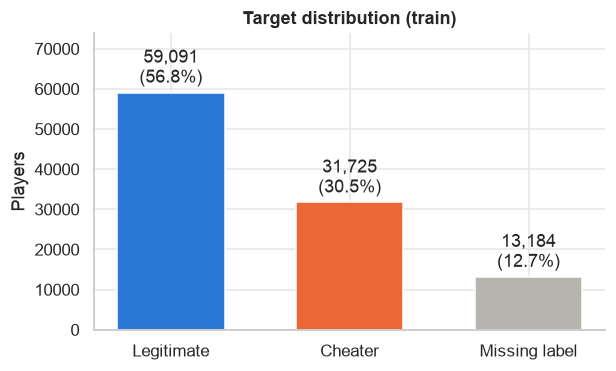

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.5))
order = ["Legitimate", "Cheater", np.nan]
values = [(train[TARGET] == 0).sum(), (train[TARGET] == 1).sum(), train[TARGET].isna().sum()]
bars = ax.bar(["Legitimate", "Cheater", "Missing label"], values, color=[C_LEGIT, C_CHEAT, "#b5b4ae"], width=0.6)
ax.bar_label(bars, labels=[f"{v:,}\n({v / len(train):.1%})" for v in values], padding=3)
ax.set(title="Target distribution (train)", ylabel="Players", ylim=(0, max(values) * 1.25))
save_fig(fig, "target-distribution")
plt.show()

Why F2 changes the picture: a model that flags **every** player gets recall = 1.
Its F2 is the floor any real model must beat.

In [13]:
f2_all_positive = fbeta_score(y, np.ones_like(y), beta=2)
print(f"F2 if we flag everyone: {f2_all_positive:.4f}")

F2 if we flag everyone: 0.7286


**Finding:** ~35% of labeled players are cheaters – moderate imbalance, not extreme.
~12.7% of train rows have no label. Flagging everyone already scores F2 ≈ 0.73,
so the decision threshold will sit **low** (favor recall).

Do unlabeled rows look like labeled rows? Compare feature means in standard-deviation units.

In [14]:
std_diff = ((unlabeled[FEATURES].mean() - lab[FEATURES].mean()) / train[FEATURES].std()).abs()
print(f"max |mean diff| = {std_diff.max():.3f} SD  ({std_diff.idxmax()})")

max |mean diff| = 0.024 SD  (level_progression_speed)


**Finding:** the unlabeled rows match the labeled rows (< 0.03 SD). The labels look missing at random, so dropping them is safe.

## 3. Missing values

Missing rate per feature, side by side for train and test.

In [15]:
missing = pd.DataFrame({
    "train": train[FEATURES].isna().mean(),
    "test": test[FEATURES].isna().mean(),
})
missing["test_minus_train"] = missing["test"] - missing["train"]
missing = missing.sort_values("train", ascending=False)
missing.to_csv(ASSETS_DIR / "missing-rate-train-vs-test.csv")
missing

,train,test,test_minus_train
survival_time_avg,0.2433,0.1306,-0.1128
weapon_switch_speed,0.2424,0.1549,-0.0876
avg_session_length_min,0.2298,0.0158,-0.2140
movement_pattern_score,0.2243,0.0872,-0.1371
friend_network_size,0.2237,0.0474,-0.1763
reports_received,0.2230,0.1493,-0.0737
aiming_smoothness,0.2087,0.0206,-0.1881
communication_rate,0.2058,0.1104,-0.0954
team_play_score,0.1946,0.0813,-0.1133
spray_control_score,0.1676,0.0557,-0.1119


Plot it. Large gaps between the bars mean train and test were masked differently.

saved assets/eda/missing-rate-train-vs-test.png


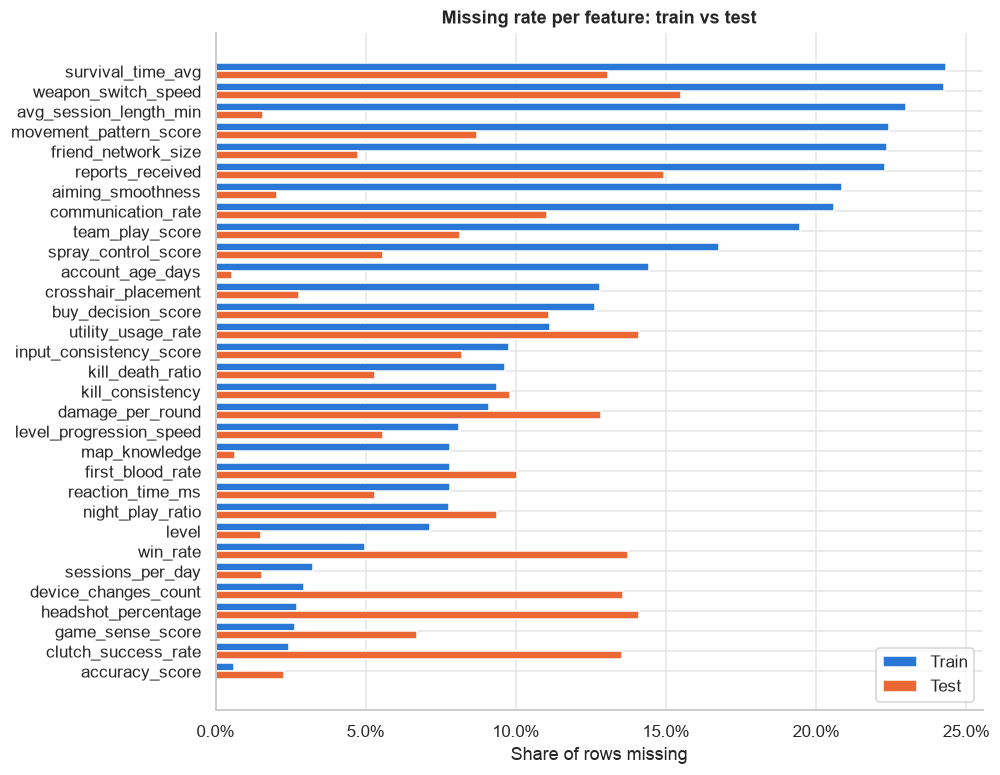

In [16]:
fig, ax = plt.subplots(figsize=(9, 8))
pos = np.arange(len(missing))
ax.barh(pos - 0.2, missing["train"], height=0.4, color=C_LEGIT, label="Train")
ax.barh(pos + 0.2, missing["test"], height=0.4, color=C_CHEAT, label="Test")
ax.set_yticks(pos, missing.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(title="Missing rate per feature: train vs test", xlabel="Share of rows missing")
ax.legend(loc="lower right")
save_fig(fig, "missing-rate-train-vs-test")
plt.show()

Missing values per row. If almost every row has a gap, dropping rows is not an option.

In [17]:
row_missing = pd.DataFrame({
    "train": train[FEATURES].isna().sum(axis=1).value_counts(normalize=True),
    "test": test[FEATURES].isna().sum(axis=1).value_counts(normalize=True),
}).fillna(0).sort_index()
print(f"rows with ≥1 NaN – train: {train[FEATURES].isna().any(axis=1).mean():.1%}   test: {test[FEATURES].isna().any(axis=1).mean():.1%}")
row_missing.T

rows with ≥1 NaN – train: 98.2%   test: 92.8%


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
train,0.0176,0.0759,0.1636,0.2221,0.2123,0.1544,0.0891,0.0419,0.0158,0.0054,0.0014,0.0005,0.0001,0.0000
test,0.0719,0.2057,0.2664,0.2215,0.1401,0.0606,0.0256,0.0063,0.0017,0.0002,0.0000,0.0000,0.0000,0.0000


Does missingness predict the target? For each feature, compare the cheater rate when the
value is missing vs present, with a chi-square test. If missingness carried signal,
a "was missing" flag would be a useful feature.

In [18]:
rows = []
for col in FEATURES:
    is_na = lab[col].isna()
    if is_na.sum() == 0:
        continue
    _, p, _, _ = chi2_contingency(pd.crosstab(is_na, y))
    rows.append({"feature": col, "rate_if_missing": y[is_na].mean(), "rate_if_present": y[~is_na].mean(), "p_value": p})
miss_vs_target = pd.DataFrame(rows).assign(diff=lambda d: d.rate_if_missing - d.rate_if_present)
miss_vs_target = miss_vs_target.sort_values("p_value").reset_index(drop=True)
miss_vs_target.head(10)

,feature,rate_if_missing,rate_if_present,p_value,diff
0,buy_decision_score,0.3591,0.3479,0.0197,0.0111
1,spray_control_score,0.3570,0.3478,0.0302,0.0092
2,aiming_smoothness,0.3559,0.3476,0.0329,0.0083
3,avg_session_length_min,0.3542,0.3479,0.0970,0.0063
4,level_progression_speed,0.3430,0.3499,0.2390,-0.0069
5,win_rate,0.3566,0.3490,0.3007,0.0077
6,game_sense_score,0.3393,0.3496,0.3081,-0.0103
7,weapon_switch_speed,0.3519,0.3485,0.3580,0.0034
8,movement_pattern_score,0.3472,0.3499,0.4771,-0.0027
9,survival_time_avg,0.3511,0.3488,0.5234,0.0024


Same check for the **count** of missing values per row.

In [19]:
n_missing = lab[FEATURES].isna().sum(axis=1).clip(upper=8)
lab.groupby(n_missing)[TARGET].agg(["mean", "size"]).rename(columns={"mean": "cheater_rate", "size": "rows"}).T

,0,1,2,3,4,5,6,7,8
cheater_rate,0.3566,0.3449,0.3485,0.3498,0.3481,0.3447,0.3564,0.3609,0.3533
rows,1607.0000,6909.0000,14880.0000,20149.0000,19335.0000,13985.0000,8080.0000,3771.0000,2100.0000


**Finding:**
- Up to ~24% missing per feature; ~98% of train rows have at least one NaN, so imputation (or NaN-aware trees) is required.
- Missing rates differ a lot between train and test for the same feature (for example `headshot_percentage` 2.7% → 14.1%).
- The cheater rate moves ≤ 1.1 percentage points when a value is missing, and is flat across the per-row NaN count. Missingness looks **MCAR** (random) and carries almost no signal.
- Conclusion: **do not add missing-indicator features.** They add little signal and their rates shift between train and test.

## 4. Feature distributions

Summary statistics on labeled rows.

In [20]:
lab[FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
kill_death_ratio,82093.0000,4.7388,1.5156,0.5000,3.7142,4.5688,5.5385,12.0000
headshot_percentage,88325.0000,47.8738,13.7520,5.0000,38.2758,47.1362,56.6382,95.0000
win_rate,86321.0000,71.3291,13.9976,16.3850,61.6157,71.1012,80.9583,100.0000
accuracy_score,90265.0000,40.1865,12.1164,8.0000,31.7074,39.6708,48.1039,85.0000
kill_consistency,82295.0000,0.6487,0.1505,0.2500,0.5434,0.6527,0.7561,0.9800
reaction_time_ms,83675.0000,135.2525,51.1627,55.0000,99.5467,128.4740,162.5436,714.4455
account_age_days,77675.0000,495.1753,351.0369,1.0054,156.3590,479.5402,762.8717,1499.6499
level,84301.0000,62.8807,20.7578,25.0057,44.9053,62.8681,80.8347,99.9988
level_progression_speed,83437.0000,0.3695,1.6393,0.0029,0.0407,0.0813,0.2141,80.0287
friend_network_size,70576.0000,137.7764,84.6514,0.0000,64.0000,135.0000,206.0000,349.0000


Spikes at the minimum or maximum suggest the data generator **clipped** values to a range.
Clipped values are real limits, not outliers – keep them, but do not treat them as errors.

In [21]:
rows = []
for col in FEATURES:
    v = train[col].dropna()
    rows.append({"feature": col, "min": v.min(), "share_at_min": (v == v.min()).mean(),
                 "max": v.max(), "share_at_max": (v == v.max()).mean()})
bounds = pd.DataFrame(rows).set_index("feature")
bounds[(bounds.share_at_min > 0.005) | (bounds.share_at_max > 0.005)].sort_values("share_at_max", ascending=False)

,min,share_at_min,max,share_at_max
feature,,,,
aiming_smoothness,0.3230,0.0000,1.0000,0.0811
device_changes_count,0.0000,0.0630,15.0000,0.0624
game_sense_score,0.4074,0.0000,1.0000,0.0416
spray_control_score,0.3500,0.0001,1.0000,0.0391
win_rate,16.3850,0.0000,100.0000,0.0297
kill_consistency,0.2500,0.0032,0.9800,0.0107
reports_received,4.0000,0.0210,29.0000,0.0070
reaction_time_ms,55.0000,0.0315,714.4455,0.0000


Class-conditional histograms for every feature (density, so class size does not distort the shape).

saved assets/eda/feature-distributions-by-class.png


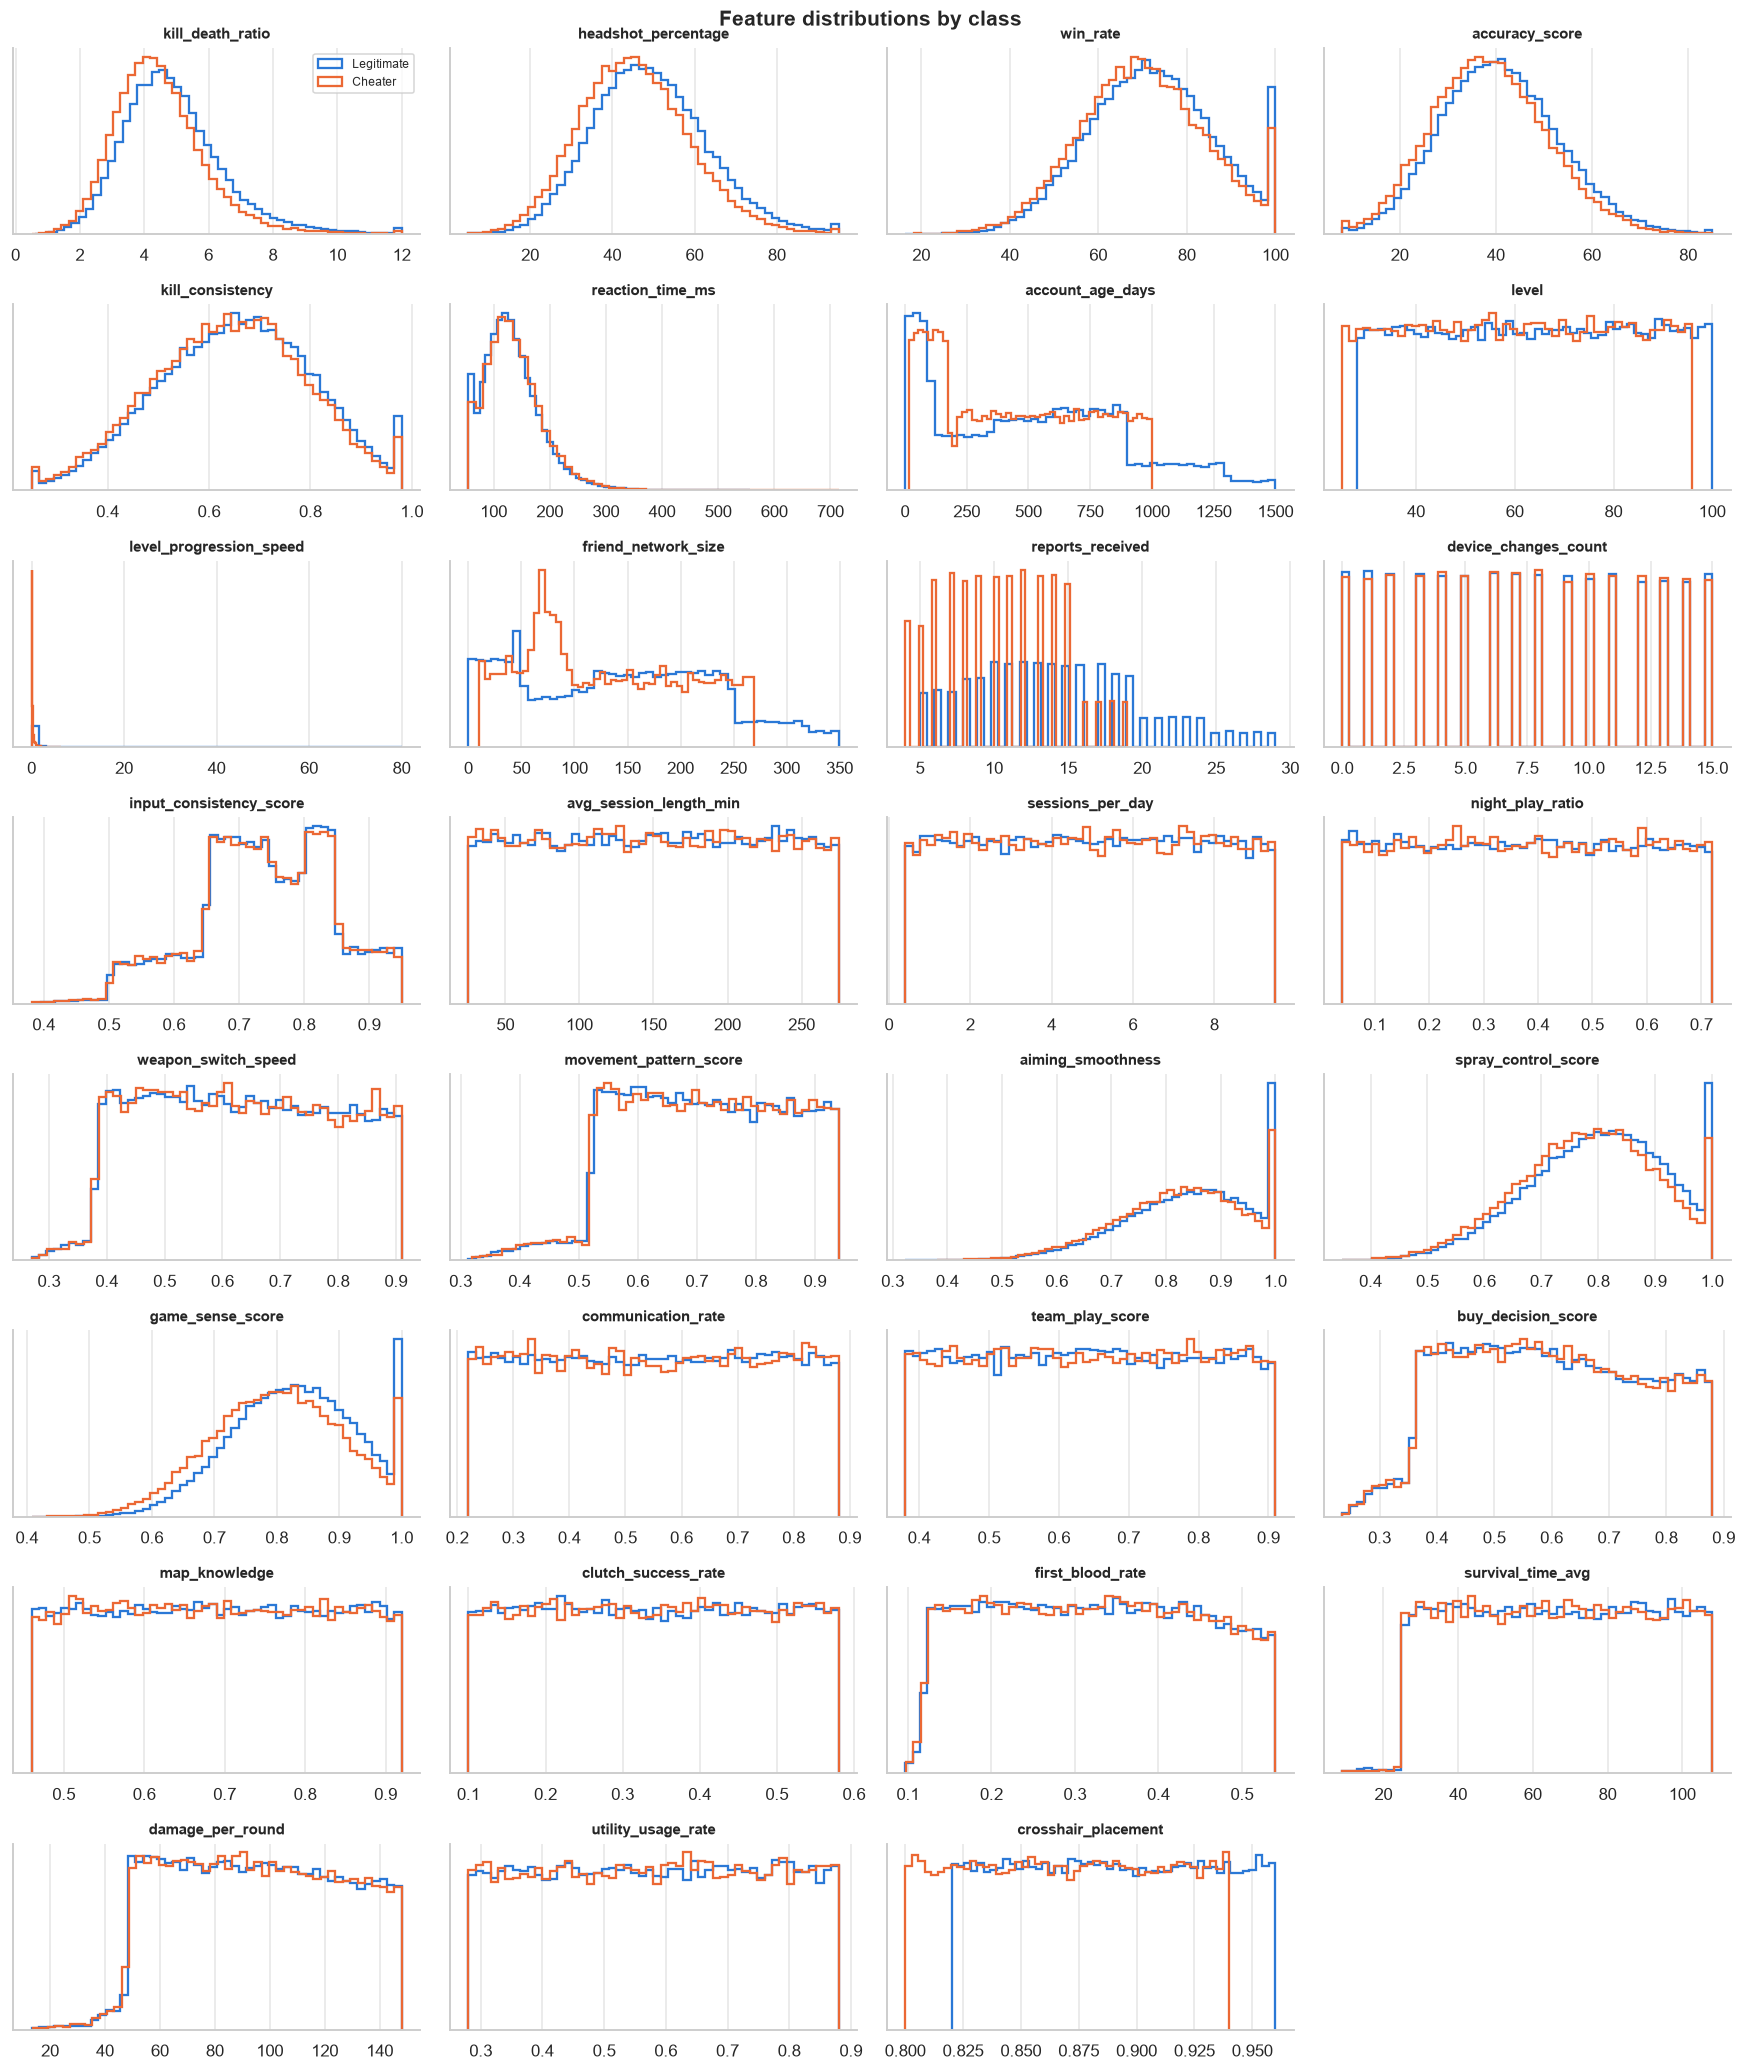

In [22]:
n_cols = 4
n_rows = int(np.ceil(len(FEATURES) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 2.4))
for ax, col in zip(axes.flat, FEATURES):
    for cls in (0, 1):
        ax.hist(lab.loc[y == cls, col].dropna(), bins=50, density=True, histtype="step",
                linewidth=1.5, color=CLASS_COLORS[cls], label=CLASS_NAMES[cls])
    ax.set_title(col, fontsize=10)
    ax.set_yticks([])
for ax in axes.flat[len(FEATURES):]:
    ax.remove()
axes.flat[0].legend(fontsize=8)
fig.suptitle("Feature distributions by class", fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, "feature-distributions-by-class")
plt.show()

**Finding:** most features overlap almost fully between classes. Visible shifts:
`reports_received`, `crosshair_placement`, `kill_death_ratio`, `headshot_percentage`,
`game_sense_score`, `accuracy_score`. Several features (`level_progression_speed`,
`reaction_time_ms`) are right-skewed – trees do not care, linear models need a log transform.

The histograms show that some features have **different ranges per class** – the edges
stop at different values. Measure it: per class min/max, and the share of labeled rows that
fall in a range only one class reaches. Those rows are "pure": the value alone decides the label.

In [23]:
rows = []
for col in FEATURES:
    v0, v1 = lab.loc[y == 0, col].dropna(), lab.loc[y == 1, col].dropna()
    lo, hi = max(v0.min(), v1.min()), min(v0.max(), v1.max())
    v = lab[col]
    rows.append({"feature": col, "legit_min": v0.min(), "legit_max": v0.max(),
                 "cheater_min": v1.min(), "cheater_max": v1.max(),
                 "share_only_legit": ((v < lo) & (v0.min() < lo) | (v > hi) & (v0.max() > hi)).mean(),
                 "share_only_cheater": ((v < lo) & (v1.min() < lo) | (v > hi) & (v1.max() > hi)).mean()})
class_ranges = pd.DataFrame(rows).set_index("feature")
class_ranges["share_pure"] = class_ranges.share_only_legit + class_ranges.share_only_cheater
class_ranges = class_ranges.sort_values("share_pure", ascending=False)
class_ranges.to_csv(ASSETS_DIR / "class-exclusive-ranges.csv")
class_ranges[class_ranges.share_pure > 0.001]

,legit_min,legit_max,cheater_min,cheater_max,share_only_legit,share_only_cheater,share_pure
feature,,,,,,,
crosshair_placement,0.8200,0.9600,0.8000,0.9400,0.0809,0.0434,0.1244
reports_received,5.0000,29.0000,4.0000,19.0000,0.0833,0.0160,0.0993
account_age_days,1.0054,1499.6499,15.0119,999.9986,0.0791,0.0000,0.0791
friend_network_size,0.0000,349.0000,10.0000,269.0000,0.0650,0.0000,0.0650
level,28.0021,99.9988,25.0057,95.9969,0.0338,0.0133,0.0471
level_progression_speed,0.0029,80.0287,0.0044,6.2549,0.0068,0.0000,0.0068


How many labeled rows sit in at least one class-only range, and how pure is that group?

In [24]:
only_legit = pd.Series(False, index=lab.index)
only_cheater = pd.Series(False, index=lab.index)
for col, r in class_ranges[class_ranges.share_pure > 0.001].iterrows():
    lo, hi = max(r.legit_min, r.cheater_min), min(r.legit_max, r.cheater_max)
    outside = (lab[col] < lo) | (lab[col] > hi)
    in_legit_range = outside & lab[col].between(r.legit_min, r.legit_max)
    only_legit |= in_legit_range
    only_cheater |= outside & ~in_legit_range

print(f"rows decided as legitimate by a range: {only_legit.mean():.1%}  (cheater rate {y[only_legit].mean():.3f})")
print(f"rows decided as cheater by a range   : {only_cheater.mean():.1%}  (cheater rate {y[only_cheater].mean():.3f})")
print(f"conflicting rows (both)              : {(only_legit & only_cheater).sum()}")
print(f"cheater rate in the remaining rows   : {y[~(only_legit | only_cheater)].mean():.3f}")

rows decided as legitimate by a range: 26.3%  (cheater rate 0.000)
rows decided as cheater by a range   : 6.9%  (cheater rate 1.000)
conflicting rows (both)              : 0
cheater rate in the remaining rows   : 0.420


**Finding:** several features have **class-only ranges** – values that only one class ever reaches.
Examples: only legitimate players have `account_age_days` > ~1000, `friend_network_size` > ~270, or
`reports_received` > 19; `crosshair_placement` < 0.82 is cheaters only. These edges alone label
**26.3% of rows as legitimate and 6.9% as cheaters, with 100% purity and no conflicts**. The remaining
67% of rows have a 42% cheater rate – that is where the model must work. Trees learn these cuts directly; this explains most of the gap
between the weak univariate AUC and the boosting probe. Other features (session length, communication,
utility usage, …) look like uniform noise with identical class shapes.

## 5. Univariate signal

Three complementary scores per feature on labeled rows:

- **ROC AUC** of the raw value (0.5 = no signal; < 0.5 = higher value → *less* likely cheater). `strength = max(AUC, 1 − AUC)`.
- **KS statistic**: largest gap between the two class CDFs.
- **Mutual information**: catches non-monotonic relations that AUC misses.

In [25]:
X_med = lab[FEATURES].fillna(lab[FEATURES].median())
mi = mutual_info_classif(X_med, y, random_state=SEED)

univariate = pd.DataFrame({
    "auc": [roc_auc_score(y, X_med[c]) for c in FEATURES],
    "ks": [ks_2samp(lab.loc[y == 1, c].dropna(), lab.loc[y == 0, c].dropna()).statistic for c in FEATURES],
    "mutual_info": mi,
}, index=FEATURES)
univariate["strength"] = np.maximum(univariate.auc, 1 - univariate.auc)
univariate["direction"] = np.where(univariate.auc >= 0.5, "higher → cheater", "lower → cheater")
univariate = univariate.sort_values("strength", ascending=False)
univariate.to_csv(ASSETS_DIR / "univariate-signal.csv")
univariate

ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/Users/beam/Workspace/Project/cpe342-ml00x/task1/.venv/lib/python3.12/site-packages/zmq/eventloop/zmqstream.py", line 566, in _log_error
    f.result()
  File "/Users/beam/Workspace/Project/cpe342-ml00x/task1/.venv/lib/python3.12/site-packages/ipykernel/kernelbase.py", line 607, in shell_channel_thread_main
    idents, msg2 = self.session.feed_identities(msg, copy=False)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/beam/Workspace/Project/cpe342-ml00x/task1/.venv/lib/python3.12/site-packages/jupyter_client/session.py", line 998, in feed_identities
    raise ValueError(msg)
ValueError: DELIM not in msg_list


,auc,ks,mutual_info,strength,direction
reports_received,0.3378,0.3111,0.0753,0.6622,lower → cheater
crosshair_placement,0.3845,0.1446,0.0791,0.6155,lower → cheater
kill_death_ratio,0.4220,0.1219,0.0081,0.5780,lower → cheater
headshot_percentage,0.4228,0.1100,0.0071,0.5772,lower → cheater
game_sense_score,0.4289,0.1014,0.0075,0.5711,lower → cheater
accuracy_score,0.4485,0.0725,0.0056,0.5515,lower → cheater
level,0.4546,0.0567,0.0283,0.5454,lower → cheater
spray_control_score,0.4593,0.0661,0.0028,0.5407,lower → cheater
win_rate,0.4605,0.0622,0.0004,0.5395,lower → cheater
account_age_days,0.4623,0.1130,0.0564,0.5377,lower → cheater


Plot AUC strength. Bar color shows the direction of the effect.

saved assets/eda/univariate-signal.png


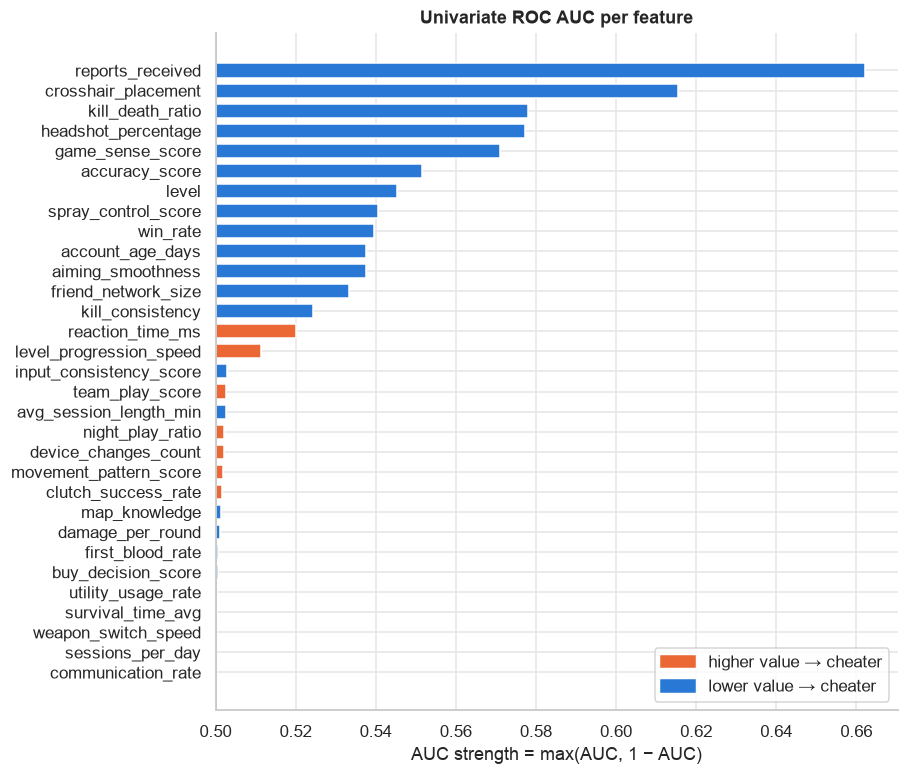

In [26]:
fig, ax = plt.subplots(figsize=(8, 8))
colors = np.where(univariate.auc >= 0.5, C_CHEAT, C_LEGIT)
ax.barh(univariate.index, univariate.strength - 0.5, left=0.5, color=colors, height=0.7)
ax.invert_yaxis()
ax.axvline(0.5, color="#888", linewidth=1)
ax.set(title="Univariate ROC AUC per feature", xlabel="AUC strength = max(AUC, 1 − AUC)", xlim=(0.5, None))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C_CHEAT), plt.Rectangle((0, 0), 1, 1, color=C_LEGIT)],
          labels=["higher value → cheater", "lower value → cheater"], loc="lower right")
save_fig(fig, "univariate-signal")
plt.show()

Count features as rates: cheater share for each value of `reports_received` and `device_changes_count`.

saved assets/eda/cheater-rate-by-count-features.png


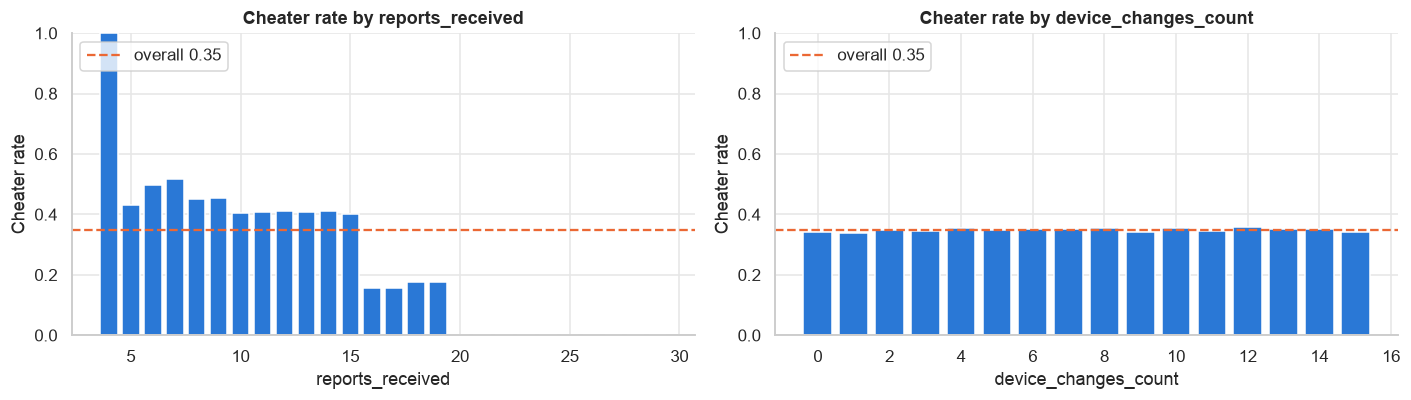

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col in zip(axes, ["reports_received", "device_changes_count"]):
    stats = lab.groupby(col)[TARGET].agg(["mean", "size"])
    ax.bar(stats.index, stats["mean"], color=C_LEGIT, width=0.8)
    ax.axhline(y.mean(), color=C_CHEAT, linestyle="--", linewidth=1.5, label=f"overall {y.mean():.2f}")
    ax.set(title=f"Cheater rate by {col}", xlabel=col, ylabel="Cheater rate", ylim=(0, 1))
    ax.legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "cheater-rate-by-count-features")
plt.show()

**Finding:** no single feature is strong – the best (`reports_received`) reaches AUC ≈ 0.66.
Every top feature points the "wrong" way for game intuition: **fewer** reports, **lower** K/D,
**lower** headshot % and accuracy → more likely cheater.
About half of the features show almost no univariate signal (AUC ≈ 0.50).
If a model does much better than 0.66, the signal must come from **combinations** of features.

## 6. Correlation

Spearman rank correlation (robust to skew and clipping) on labeled rows.

saved assets/eda/correlation-matrix.png


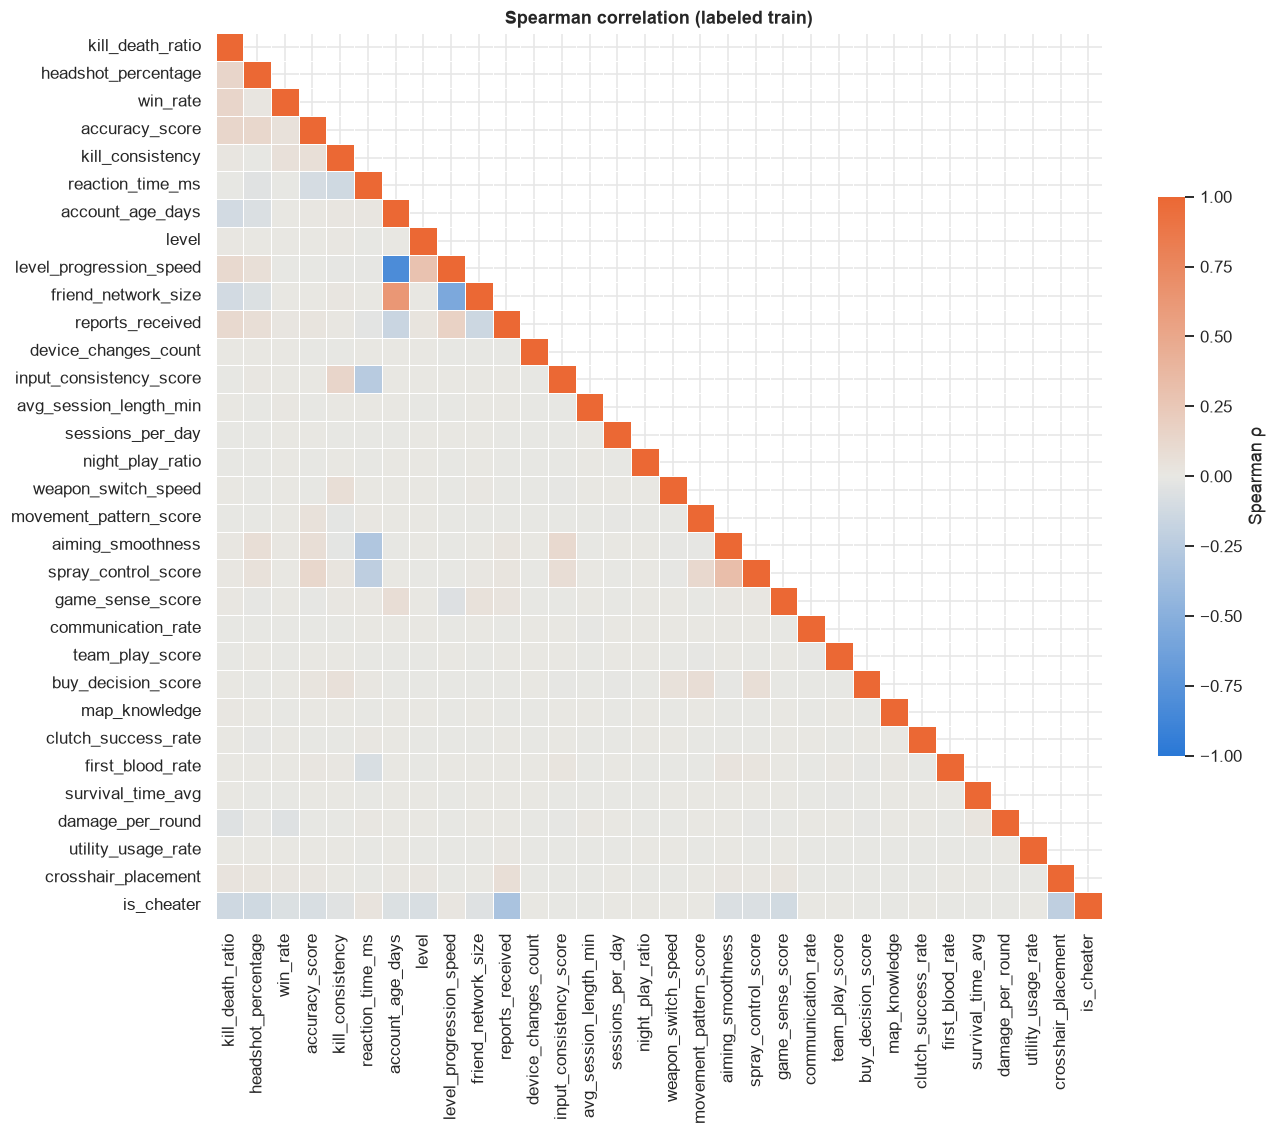

In [28]:
corr = lab[FEATURES + [TARGET]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, square=True,
            linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.6, "label": "Spearman ρ"}, ax=ax)
ax.set_title("Spearman correlation (labeled train)")
save_fig(fig, "correlation-matrix")
plt.show()

Strongest feature pairs. Very high |ρ| means redundant features.

In [29]:
pairs = corr.loc[FEATURES, FEATURES].where(np.triu(np.ones((len(FEATURES),) * 2, dtype=bool), k=1)).stack()
pairs = pairs.rename("rho").reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
pairs.reindex(pairs.rho.abs().sort_values(ascending=False).index).head(15).reset_index(drop=True)

,feature_a,feature_b,rho
0,account_age_days,level_progression_speed,-0.8136
1,account_age_days,friend_network_size,0.6294
2,level_progression_speed,friend_network_size,-0.5663
3,aiming_smoothness,spray_control_score,0.3218
4,reaction_time_ms,aiming_smoothness,-0.2954
5,level,level_progression_speed,0.2922
6,reaction_time_ms,input_consistency_score,-0.2555
7,reaction_time_ms,spray_control_score,-0.2223
8,level_progression_speed,reports_received,0.1698
9,account_age_days,reports_received,-0.1596


**Finding:** one strong block: `account_age_days`, `level_progression_speed` (ρ ≈ −0.81),
and `friend_network_size` (ρ ≈ 0.63) all describe **account maturity**. A second, weaker
block links aim mechanics (`reaction_time_ms`, `aiming_smoothness`, `spray_control_score`).
Skill stats (K/D, headshot %, accuracy) are almost independent (|ρ| < 0.15).
No pair is redundant enough to drop.

## 7. Feature interactions

Univariate signal is weak, so look at pairs. Each heatmap bins two features into
deciles and shows the cheater rate per cell. A pattern that is not a simple
gradient along one axis means an **interaction** a tree model can learn.

saved assets/eda/interaction-heatmaps.png


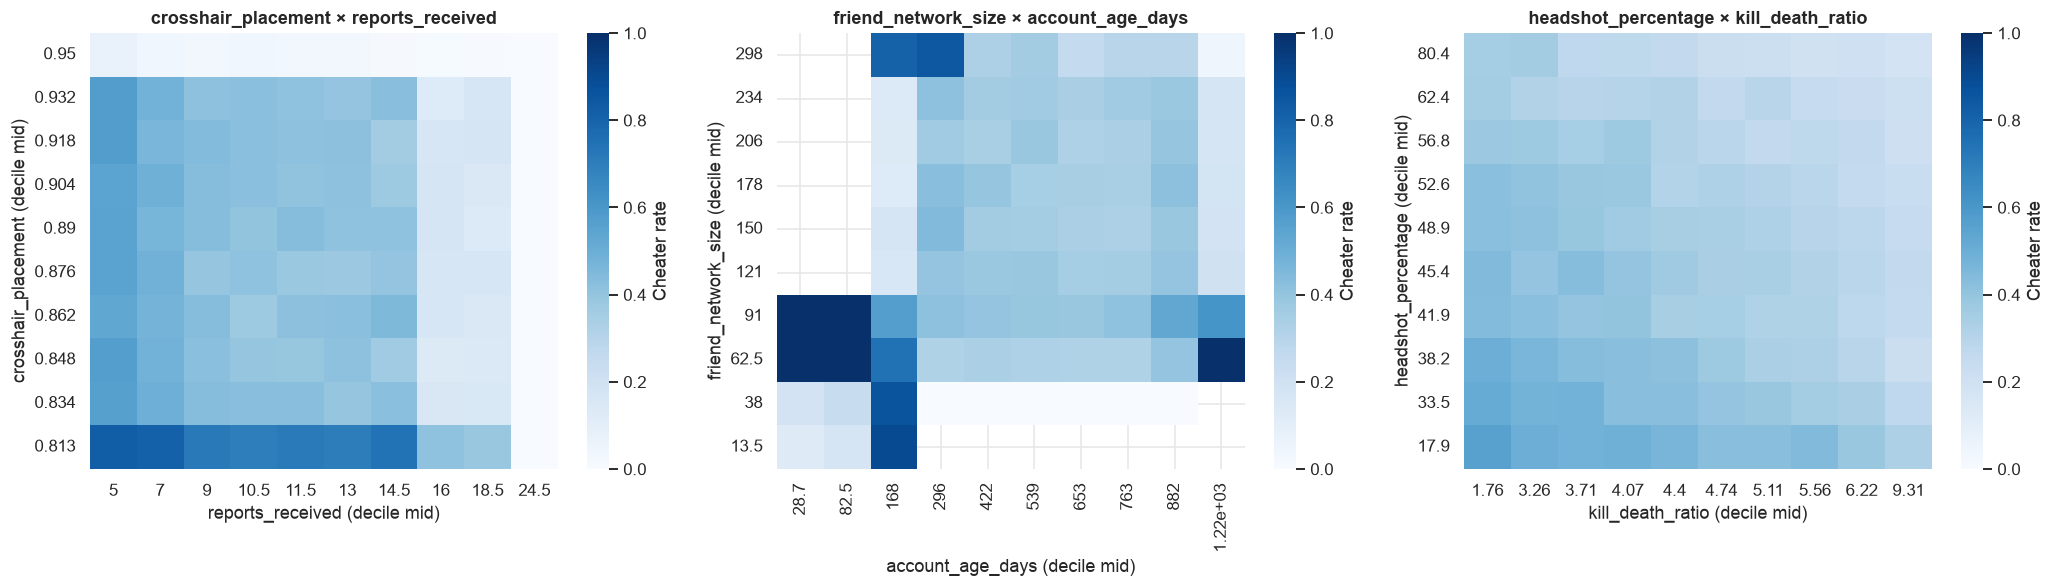

In [30]:
INTERACTION_PAIRS = [
    ("reports_received", "crosshair_placement"),
    ("account_age_days", "friend_network_size"),
    ("kill_death_ratio", "headshot_percentage"),
]

def decile_rate(df, col_x, col_y):
    d = df[[col_x, col_y, TARGET]].dropna()
    bx = pd.qcut(d[col_x], 10, duplicates="drop")
    by = pd.qcut(d[col_y], 10, duplicates="drop")
    return d.groupby([by, bx], observed=True)[TARGET].mean().unstack()

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, (cx, cy) in zip(axes, INTERACTION_PAIRS):
    grid = decile_rate(lab, cx, cy).iloc[::-1]
    sns.heatmap(grid, cmap=SEQUENTIAL, vmin=0, vmax=1, ax=ax, cbar_kws={"label": "Cheater rate"},
                xticklabels=[f"{i.mid:.3g}" for i in grid.columns], yticklabels=[f"{i.mid:.3g}" for i in grid.index])
    ax.set(title=f"{cy} × {cx}", xlabel=f"{cx} (decile mid)", ylabel=f"{cy} (decile mid)")
    ax.tick_params(axis="y", labelrotation=0)
fig.tight_layout()
save_fig(fig, "interaction-heatmaps")
plt.show()

**Finding:**
- `crosshair_placement` in its lowest decile (≤ ~0.82) → almost every player is a cheater, at any report count.
- More than ~15 reports → cheater rate drops to ~10%. **More reports means *less* likely cheater** – the opposite of intuition.
- Account maturity has sharp zones: young accounts (< ~170 days) with 60–90 friends are almost all cheaters;
  accounts older than ~250 days with < 40 friends are almost never cheaters.
- K/D × headshot % shows only a smooth gradient: low K/D and low headshot % → slightly more cheaters.

The sharp, rectangular zones look like **threshold rules** in the data generator. Trees fit
these well; linear models do not. Trust the data, not game intuition – the direction of the effects is often reversed.

## 8. Multivariate signal probe

Two quick, **untuned** probes with 5-fold stratified out-of-fold (OOF) predictions:

- Logistic regression (linear, additive effects only).
- Histogram gradient boosting (non-linear, interactions, NaN-aware).

A large gap between them confirms that interactions matter. These are probes for EDA, not the final model.

In [31]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
X_lab = lab[FEATURES]

logreg = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000))
oof_lr = cross_val_predict(logreg, X_lab, y, cv=cv, method="predict_proba")[:, 1]

hgb = HistGradientBoostingClassifier(random_state=SEED)
oof_hgb = cross_val_predict(hgb, X_lab, y, cv=cv, method="predict_proba")[:, 1]

Compare the probes on threshold-free metrics.

In [32]:
probe = pd.DataFrame({
    "ROC AUC": [roc_auc_score(y, oof_lr), roc_auc_score(y, oof_hgb)],
    "PR AUC": [average_precision_score(y, oof_lr), average_precision_score(y, oof_hgb)],
}, index=["Logistic regression", "HistGradientBoosting"])
probe

,ROC AUC,PR AUC
Logistic regression,0.7649,0.6264
HistGradientBoosting,0.8898,0.8306


F2 against the decision threshold for the boosting probe. This shows where the
F2-optimal threshold sits and how flat the curve is near the top.

In [33]:
precision, recall, thresholds = precision_recall_curve(y, oof_hgb)
precision, recall = precision[:-1], recall[:-1]
f2 = 5 * precision * recall / np.clip(4 * precision + recall, 1e-12, None)
best = np.argmax(f2)
print(f"best OOF F2 = {f2[best]:.4f} at threshold {thresholds[best]:.3f} "
      f"(precision {precision[best]:.3f}, recall {recall[best]:.3f})")
print(f"F2 at default 0.5 threshold = {fbeta_score(y, oof_hgb >= 0.5, beta=2):.4f}")

best OOF F2 = 0.8367 at threshold 0.186 (precision 0.529, recall 0.979)
F2 at default 0.5 threshold = 0.6191


saved assets/eda/f2-threshold-curve.png


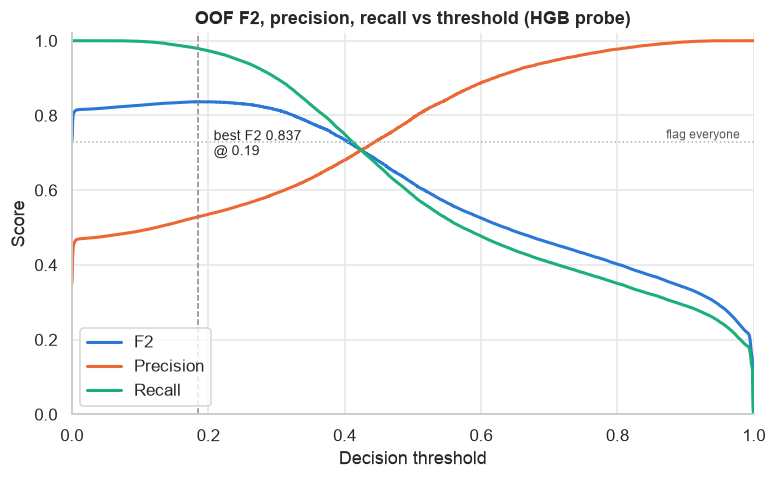

In [34]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, f2, color=C_LEGIT, linewidth=2)
ax.plot(thresholds, precision, color=C_CHEAT, linewidth=2)
ax.plot(thresholds, recall, color=C_THIRD, linewidth=2)
ax.axvline(thresholds[best], color="#888", linestyle="--", linewidth=1)
ax.annotate(f"best F2 {f2[best]:.3f}\n@ {thresholds[best]:.2f}", (thresholds[best], f2[best]),
            xytext=(10, -35), textcoords="offset points", fontsize=9)
ax.axhline(f2_all_positive, color="#b5b4ae", linestyle=":", linewidth=1)
ax.text(0.98, f2_all_positive + 0.01, "flag everyone", ha="right", fontsize=8, color="#555")
ax.set(title="OOF F2, precision, recall vs threshold (HGB probe)", xlabel="Decision threshold", ylabel="Score", xlim=(0, 1), ylim=(0, 1.02))
legend = [plt.Line2D([], [], color=c, linewidth=2) for c in (C_LEGIT, C_CHEAT, C_THIRD)]
ax.legend(legend, ["F2", "Precision", "Recall"], loc="lower left")
save_fig(fig, "f2-threshold-curve")
plt.show()

Which features does the boosting probe use? Permutation importance on a held-out 20% split
(drop in ROC AUC when one feature is shuffled). This catches features that help only through interactions.

In [35]:
X_fit, X_hold, y_fit, y_hold = train_test_split(X_lab, y, test_size=0.2, stratify=y, random_state=SEED)
hgb_fit = HistGradientBoostingClassifier(random_state=SEED).fit(X_fit, y_fit)
perm = permutation_importance(hgb_fit, X_hold, y_hold, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
importance = pd.DataFrame({"importance": perm.importances_mean, "std": perm.importances_std}, index=FEATURES)
importance = importance.join(univariate[["strength"]].rename(columns={"strength": "univariate_auc"}))
importance = importance.sort_values("importance", ascending=False)
importance.to_csv(ASSETS_DIR / "permutation-importance.csv")
importance

,importance,std,univariate_auc
reports_received,0.1060,0.0011,0.6622
crosshair_placement,0.1020,0.0027,0.6155
friend_network_size,0.0982,0.0024,0.5333
account_age_days,0.0974,0.0023,0.5377
level,0.0241,0.0011,0.5454
game_sense_score,0.0111,0.0008,0.5711
headshot_percentage,0.0079,0.0003,0.5772
kill_death_ratio,0.0063,0.0010,0.5780
accuracy_score,0.0032,0.0003,0.5515
level_progression_speed,0.0024,0.0002,0.5113


saved assets/eda/permutation-importance.png


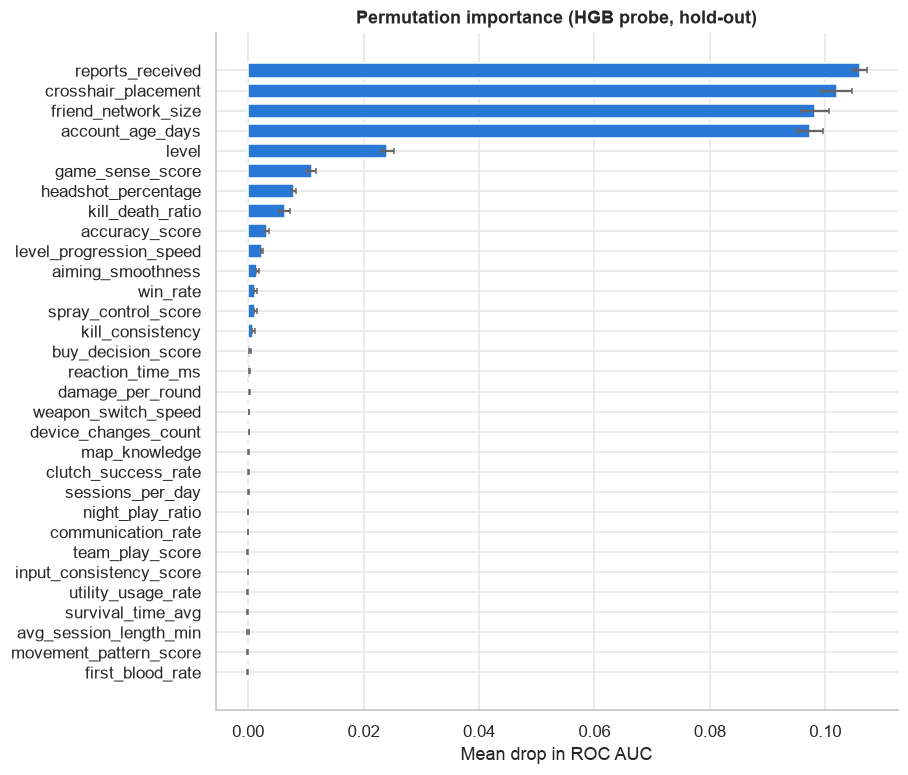

In [36]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(importance.index, importance.importance, xerr=importance["std"], color=C_LEGIT, height=0.7,
        error_kw={"ecolor": "#666", "capsize": 2})
ax.invert_yaxis()
ax.set(title="Permutation importance (HGB probe, hold-out)", xlabel="Mean drop in ROC AUC")
save_fig(fig, "permutation-importance")
plt.show()

**Finding:** four features carry most of the signal: `reports_received`, `crosshair_placement`,
`friend_network_size`, `account_age_days` (each ≈ 0.10 AUC drop). The last two are weak alone
(univariate AUC ≈ 0.53) but strong in the model – their signal comes from **interactions**
(see the account-maturity heatmap in section 7). About 15 features add ≈ 0 – candidates
to drop, to confirm with OOF tests during modeling.

## 9. Train vs test shift (adversarial validation)

Label train rows 0 and test rows 1, then train a classifier to tell them apart.
AUC ≈ 0.5 means the same distribution. We run it twice:

1. **Raw** features (with NaN).
2. **Values only**: each NaN filled with a random draw from that column's observed values
   (pooled train + test). This hides the missing *pattern*. A median fill would not: the
   spike at the median still marks where values were missing.
3. **Missing pattern only**: 0/1 "is NaN" matrix, no values.

If (1) and (3) are high and (2) is ≈ 0.5, the shift comes only from how values were masked.

In [37]:
def adversarial_auc(train_X, test_X):
    X = pd.concat([train_X, test_X], ignore_index=True)
    is_test = np.r_[np.zeros(len(train_X)), np.ones(len(test_X))]
    folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    pred = cross_val_predict(HistGradientBoostingClassifier(random_state=SEED), X, is_test, cv=folds, method="predict_proba")[:, 1]
    return roc_auc_score(is_test, pred)

def random_fill(df, pool, seed=SEED):
    rng = np.random.default_rng(seed)
    out = df.copy()
    for col in FEATURES:
        na = out[col].isna()
        out.loc[na, col] = rng.choice(pool[col].dropna().to_numpy(), size=na.sum())
    return out

pool = pd.concat([train[FEATURES], test[FEATURES]])
adversarial = pd.Series({
    "raw (with NaN)": adversarial_auc(train[FEATURES], test[FEATURES]),
    "values only (NaN → random draw)": adversarial_auc(random_fill(train[FEATURES], pool), random_fill(test[FEATURES], pool, SEED + 1)),
    "missing pattern only": adversarial_auc(train[FEATURES].isna().astype(int), test[FEATURES].isna().astype(int)),
}, name="adversarial ROC AUC")
adversarial.to_frame()

,adversarial ROC AUC
raw (with NaN),0.9007
values only (NaN → random draw),0.5503
missing pattern only,0.9026


Per-feature check on observed values only: KS statistic between train and test.

In [38]:
shift = pd.DataFrame({
    "ks_train_vs_test": [ks_2samp(train[c].dropna(), test[c].dropna()).statistic for c in FEATURES],
    "mean_train": train[FEATURES].mean().values,
    "mean_test": test[FEATURES].mean().values,
}, index=FEATURES).sort_values("ks_train_vs_test", ascending=False)
shift.head(10)

,ks_train_vs_test,mean_train,mean_test
crosshair_placement,0.0107,0.8829,0.8835
utility_usage_rate,0.0104,0.5812,0.5791
damage_per_round,0.0102,95.5616,95.7924
communication_rate,0.0099,0.5500,0.5527
input_consistency_score,0.0096,0.7397,0.7418
buy_decision_score,0.0094,0.5972,0.5946
movement_pattern_score,0.0084,0.7148,0.7132
win_rate,0.0083,71.3615,71.3009
kill_death_ratio,0.0074,4.7380,4.7228
team_play_score,0.0072,0.6444,0.6434


**Finding:** raw and pattern-only adversarial AUC are ≈ 0.90 – train and test are easy to
tell apart. Once the pattern is hidden, the score falls to ≈ 0.55, and every per-feature
KS is ≈ 0.01.
The **values** in train and test come from the same distribution; only the **masking rates** differ.

Implications:
- Random stratified K-fold on train is a fair proxy for test.
- NaN-aware models must not lean on *which* columns are missing. Missing indicators would
  learn train-specific masking rates. Prefer imputation, or check that NaN-native handling
  does not hurt OOF vs. an imputed variant.

## 10. Summary and modeling decisions

| # | Finding | Decision |
|---|---------|----------|
| 1 | 35% cheaters among labeled rows; 12.7% of train rows have no label, and they look like labeled rows. | Train on the 90,816 labeled rows. Use `StratifiedKFold`. Unlabeled train rows are an optional semi-supervised source (train rows only – never test). |
| 2 | F2 weights recall 4×; "flag everyone" already scores F2 ≈ 0.73. | Tune the threshold on OOF predictions. Expect it well below 0.5 (probe: best F2 0.837 at ≈ 0.19 vs 0.619 at 0.5). Report F2 at the tuned threshold, plus PR AUC. |
| 3 | Imbalance is moderate. | Start with `class_weight` / `scale_pos_weight` or no weighting + threshold tuning. SMOTE is low priority: threshold tuning covers most of the gain. |
| 4 | ~98% of rows have ≥1 NaN; missingness is random w.r.t. the target. | Keep all rows. Use median / iterative imputation or NaN-native GBDTs. **No missing-indicator features.** |
| 5 | Train vs test differ only in per-column missing rates; values match. | Random K-fold OOF is a valid proxy for test. Validate that the imputation choice is robust to the masking shift. |
| 6 | Univariate signal is weak (best AUC ≈ 0.66). OOF ROC AUC: logistic regression 0.76 vs boosting 0.89. | Signal lives in **interactions** → gradient-boosted trees (LightGBM / XGBoost / CatBoost) + ensemble. Try features from the top four, e.g. `friend_network_size / account_age_days`, reports per day of account age. |
| 6a | Class-only value ranges (account age, friends, reports, crosshair, level) label 33% of rows with 100% purity. | Keep raw values (no clipping/winsorizing that would erase the edges). Trees capture the cuts; count of "pure-range" hits is a cheap engineered feature to test. |
| 7a | Sharp rule-like zones (`crosshair_placement` ≤ ~0.82 → ~100% cheaters; > 15 reports → ~10%). Effect directions defy game intuition. | Tree models will find these cuts. Do not hand-craft features from domain intuition without an OOF check. |
| 7 | Several features clip at bounds (`aiming_smoothness = 1.0`, `device_changes_count` 0/15, `reaction_time_ms = 55`). | Keep clipped values; optional "at bound" flags are cheap to test. |
| 8 | Account-maturity block is correlated (ρ up to −0.81); ~15 features have ≈ 0 permutation importance. | Keep all 31 features as a start. Test dropping the zero-importance ones by OOF F2, not by univariate score. |

Artifacts saved to `assets/eda/`: target distribution, missing-rate comparison, class-conditional
distributions, univariate signal, count-feature rates, correlation matrix, interaction heatmaps,
F2-threshold curve, permutation importance, plus CSV tables.